# Air Quality Forecasting with Machine Learning: Reproducing the Base Paper

**Machine Learning course project, FAST-NUCES. Group 56:** 

Maham Anjum (24I-0053), Romaisa (24I-0061), Section AI-5C.

**Base paper:** Özüpak, Alpsalaz & Aslan (2025). *Air Quality Forecasting Using Machine Learning: Comparative Analysis and Ensemble Strategies for Enhanced Prediction.* Water, Air, & Soil Pollution 236:464. https://doi.org/10.1007/s11270-025-08122-8

This notebook follows the paper's method step by step:

1. Load and explore the UCI/Kaggle Air Quality dataset (paper Figs. 2–5, Table 2).
2. Clean the data: missing values, outlier removal, 80/20 split in time order.
3. Train the paper's 10 regression models with default settings ("No Optimization").
4. Train them again with the paper's own hyperparameters (Table 3).
5. Tune them with Bayesian optimisation and randomized cross-validation, using the paper's search ranges.
6. Compare our results with the paper's Table 4.
7. Reproduce the paper's headline result (SVR, R² = 0.9994).
8. Combine models with stacking and test the paper's "15–20% lower RMSE" claim.
9. Explain the models with Pearson correlation, SHAP and partial dependence plots.

**How to run:**
- Download the dataset from https://www.kaggle.com/datasets/fedesoriano/air-quality-data-set and save it next to this notebook as *AirQuality.csv*.
- Install the libraries: *pip install numpy pandas matplotlib seaborn scikit-learn xgboost lightgbm catboost optuna shap*
- Run *Kernel → Restart & Run All*.

**Target variable.** The paper never says which pollutant it predicts. We predict benzene, *C6H6(GT)*. Section 10 shows why this is almost certainly the paper's target.

## 1. Setup
All settings are in one place. SEED is used everywhere, so every run gives the same numbers.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, StackingRegressor
from sklearn.inspection import PartialDependenceDisplay
from sklearn.linear_model import BayesianRidge, ElasticNet, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid", palette="tab10")   # coloured figures everywhere

DATA_PATH = "AirQuality.csv"   # the Kaggle/UCI file
TARGET = "C6H6(GT)"            # benzene
SEED = 42                      # one random seed for everything
N_TRIALS = 20                  # Bayesian optimisation trials per model
CV_FOLDS = 5                   # folds for randomized cross-validation

# Library versions (for the report and for reproducibility)
import catboost, lightgbm, sklearn, sys, xgboost
for lib in (np, pd, sklearn, xgboost, lightgbm, catboost, optuna):
    print(f"{lib.__name__:12s} {lib.__version__}")
print(f"{'python':12s} {sys.version.split()[0]}")

numpy        2.4.6
pandas       3.0.6
sklearn      1.9.1
xgboost      3.4.1
lightgbm     4.7.0
catboost     1.2.10
optuna       5.0.0
python       3.13.9


## 2. Load the data
The file has three quirks: `;` separates columns, `,` is the decimal mark, and `-200` means "no measurement". We turn *-200* into a proper missing value (NaN).

In [2]:
raw = pd.read_csv(DATA_PATH, sep=";", decimal=",")
raw = raw.dropna(axis=1, how="all").dropna(how="all")      # drop empty trailing columns/rows

raw["datetime"] = pd.to_datetime(raw["Date"] + " " + raw["Time"], format="%d/%m/%Y %H.%M.%S")
raw = raw.drop(columns=["Date", "Time"]).sort_values("datetime").reset_index(drop=True)
raw = raw.replace(-200, np.nan)

print("Rows:", len(raw), "| Columns:", raw.shape[1])
print("From", raw["datetime"].min(), "to", raw["datetime"].max())
raw.head()

Rows: 9357 | Columns: 14
From 2004-03-10 18:00:00 to 2005-04-04 14:00:00


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,datetime
0,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00
1,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00
2,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00
3,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00
4,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00


In [3]:
missing = raw.isna().mean().mul(100).round(1).sort_values(ascending=False)
missing.to_frame("missing %").T

,NMHC(GT),CO(GT),NOx(GT),NO2(GT),C6H6(GT),PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,datetime
missing %,90.2,18.0,17.5,17.5,3.9,3.9,3.9,3.9,3.9,3.9,3.9,3.9,3.9,0.0


9,357 hourly rows, matching the paper. *NMHC(GT)* is about 90% empty, so it is useless as a feature. The other columns miss between 4% and 18% of their values.

## 3. Exploratory data analysis
### 3.1 Descriptive statistics (paper Table 2)

In [4]:
numeric = raw.drop(columns="datetime")
stats = numeric.agg(["mean", "median", "std", "min", "max"]).T
stats

,mean,median,std,min,max
CO(GT),2.1527,1.8000,1.4533,0.1000,11.900
PT08.S1(CO),1099.8332,1063.0000,217.0800,647.0000,2040.000
NMHC(GT),218.8118,150.0000,204.4599,7.0000,1189.000
C6H6(GT),10.0831,8.2000,7.4498,0.1000,63.700
PT08.S2(NMHC),939.1534,909.0000,266.8314,383.0000,2214.000
NOx(GT),246.8967,180.0000,212.9792,2.0000,1479.000
PT08.S3(NOx),835.4936,806.0000,256.8173,322.0000,2683.000
NO2(GT),113.0913,109.0000,48.3701,2.0000,340.000
PT08.S4(NO2),1456.2646,1463.0000,346.2068,551.0000,2775.000
PT08.S5(O3),1022.9061,963.0000,398.4843,221.0000,2523.000


**Comparison with the paper.** Several values in the paper's Tables 1–2 do not match the real data. For example, the true maximum of *CO(GT)* is 11.9 (paper: 9.4), of *NOx(GT)* 1479 (paper: 296), of *PT08.S2(NMHC)* 2214 (paper: 5000), and of *AH* 2.23 (paper: 0.03). The paper's tables look rounded or estimated rather than computed from the file.

### 3.2 Weekly time series (paper Fig. 2)

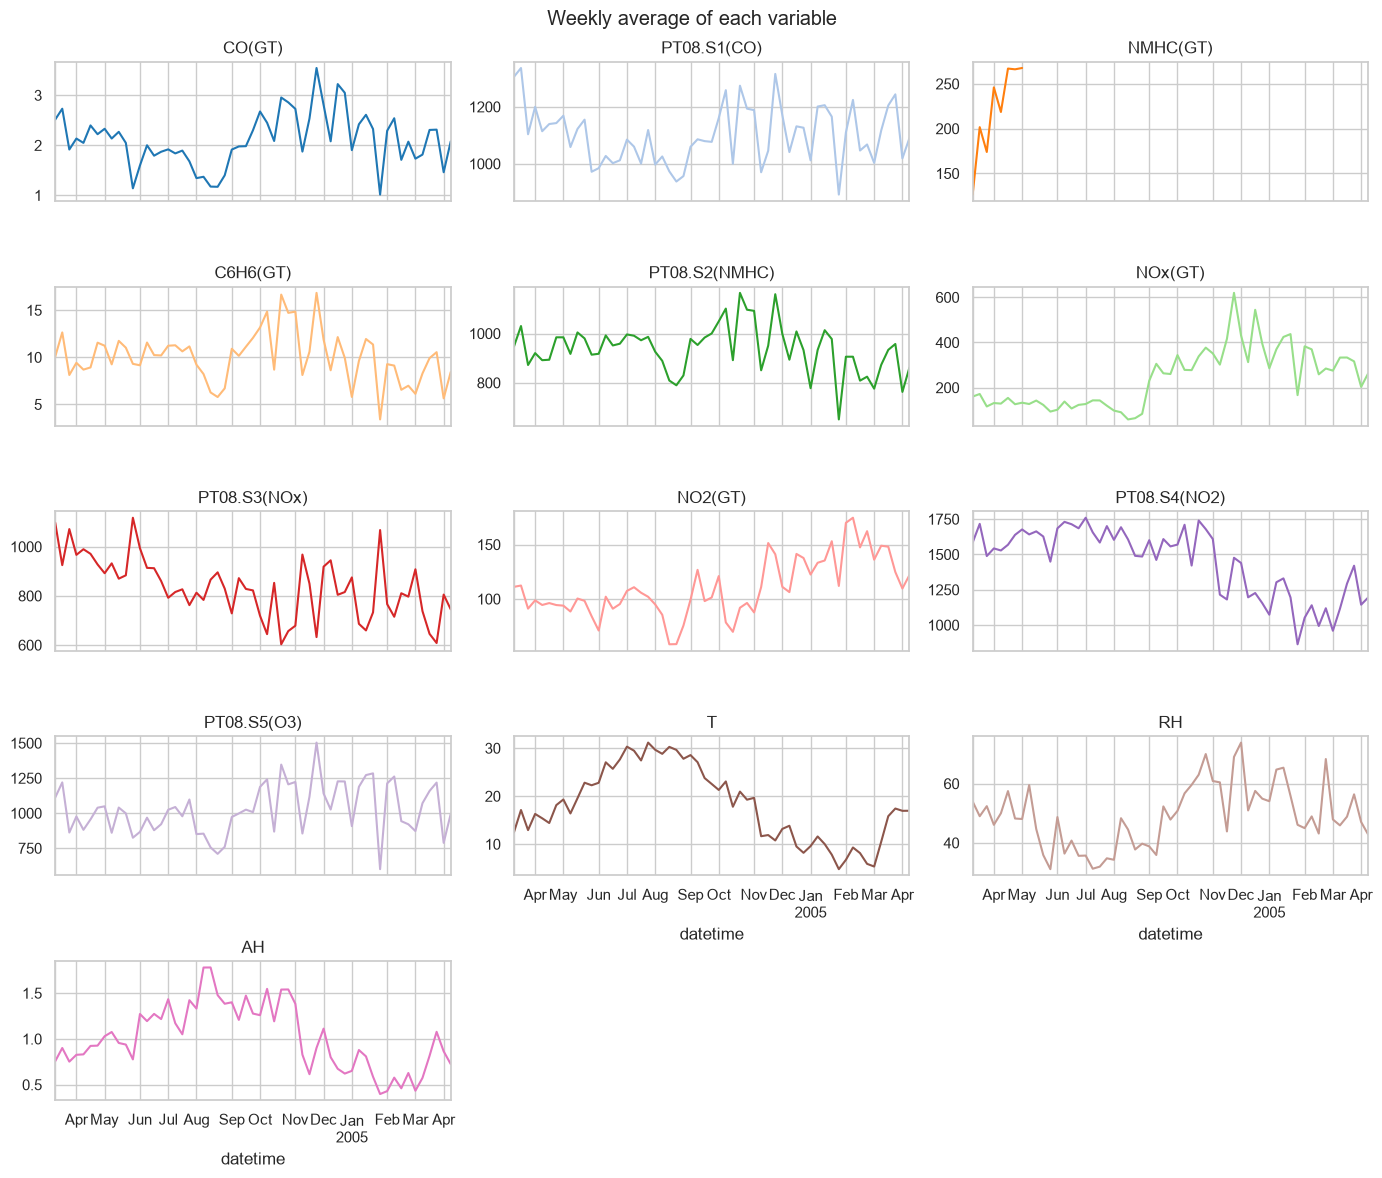

In [5]:
weekly = raw.set_index("datetime").resample("W").mean()
colors = sns.color_palette("tab20", weekly.shape[1])
weekly.plot(subplots=True, layout=(5, 3), figsize=(14, 12), legend=False, title=list(weekly.columns), color=colors)
plt.suptitle("Weekly average of each variable")
plt.tight_layout()
plt.show()

CO, NOx and benzene rise in winter (heating and traffic). Temperature follows a smooth yearly cycle. These seasonal patterns match the paper's description.

### 3.3 Correlation matrix (paper Fig. 3)

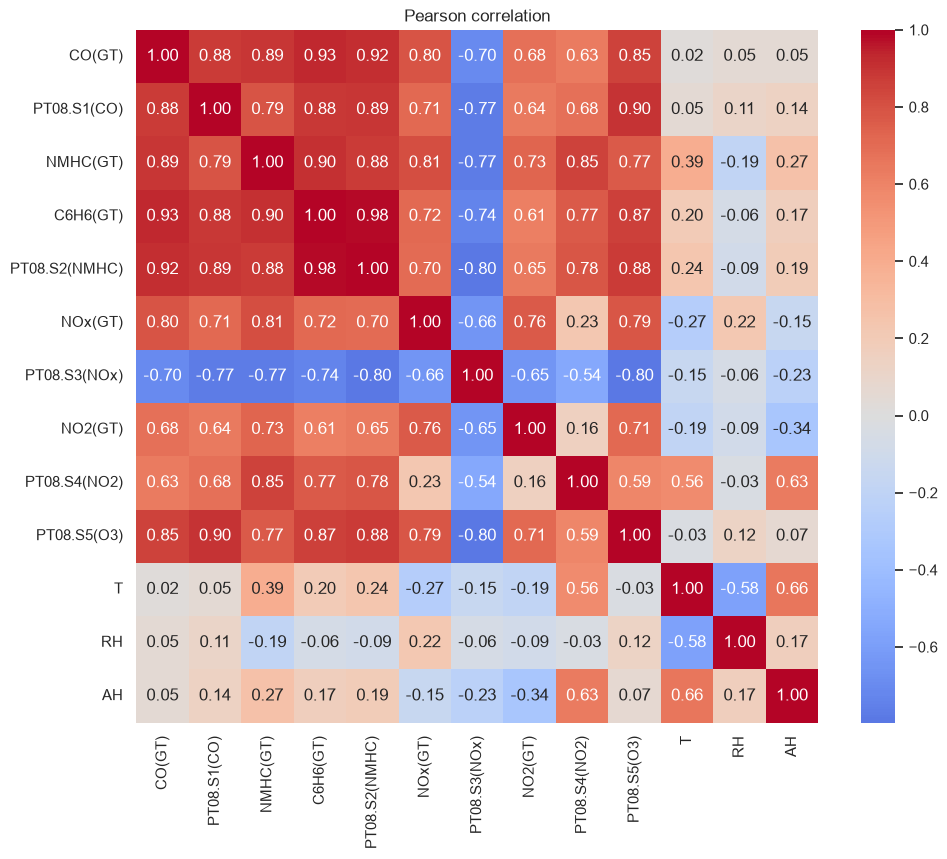

In [6]:
corr = numeric.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Pearson correlation")
plt.show()

In [7]:
# The correlations quoted in the paper's text, next to the real values
paper_corr = [
    ("CO(GT)", "NOx(GT)", 0.78), ("CO(GT)", "NO2(GT)", 0.71), ("PT08.S1(CO)", "CO(GT)", 0.90),
    ("CO(GT)", "T", -0.097), ("NOx(GT)", "NO2(GT)", 0.88), ("NOx(GT)", "PT08.S4(NO2)", 0.82),
    ("NOx(GT)", "T", -0.23), ("PT08.S5(O3)", "T", 0.69), ("AH", "NO2(GT)", -0.15),
    ("AH", "CO(GT)", -0.15), ("T", "AH", 0.69),
]
pd.DataFrame(
    [(f"{a} vs {b}", corr.loc[a, b], p) for a, b, p in paper_corr],
    columns=["Pair", "Our data", "Paper"],
).round(2)

,Pair,Our data,Paper
0,CO(GT) vs NOx(GT),0.80,0.78
1,CO(GT) vs NO2(GT),0.68,0.71
2,PT08.S1(CO) vs CO(GT),0.88,0.90
3,CO(GT) vs T,0.02,-0.10
4,NOx(GT) vs NO2(GT),0.76,0.88
5,NOx(GT) vs PT08.S4(NO2),0.23,0.82
6,NOx(GT) vs T,-0.27,-0.23
7,PT08.S5(O3) vs T,-0.03,0.69
8,AH vs NO2(GT),-0.34,-0.15
9,AH vs CO(GT),0.05,-0.15


**Comparison with the paper.** Five correlations agree closely (CO–NOx, CO–NO2, sensor S1–CO, NOx–T, T–AH). Three differ strongly: NOx vs the S4 sensor (0.23, paper 0.82), the O3 sensor vs temperature (about 0, paper 0.69), and NOx vs NO2 (0.76, paper 0.88). Three weak ones also differ: CO vs T and AH vs CO have the opposite sign to the paper, and AH vs NO2 is stronger (−0.34, paper −0.15). We could not find a cleaning step that produces the paper's values.

In [8]:
corr[TARGET].drop(TARGET).sort_values(ascending=False).to_frame("correlation with benzene")

,correlation with benzene
PT08.S2(NMHC),0.9820
CO(GT),0.9311
NMHC(GT),0.9026
PT08.S1(CO),0.8838
PT08.S5(O3),0.8657
PT08.S4(NO2),0.7657
NOx(GT),0.7188
NO2(GT),0.6145
T,0.1990
AH,0.1680


Benzene is almost perfectly correlated with the `PT08.S2(NMHC)` sensor (about 0.98). Section 10 shows this is the key to the paper's very high scores.

### 3.4 Box plots (paper Fig. 4)

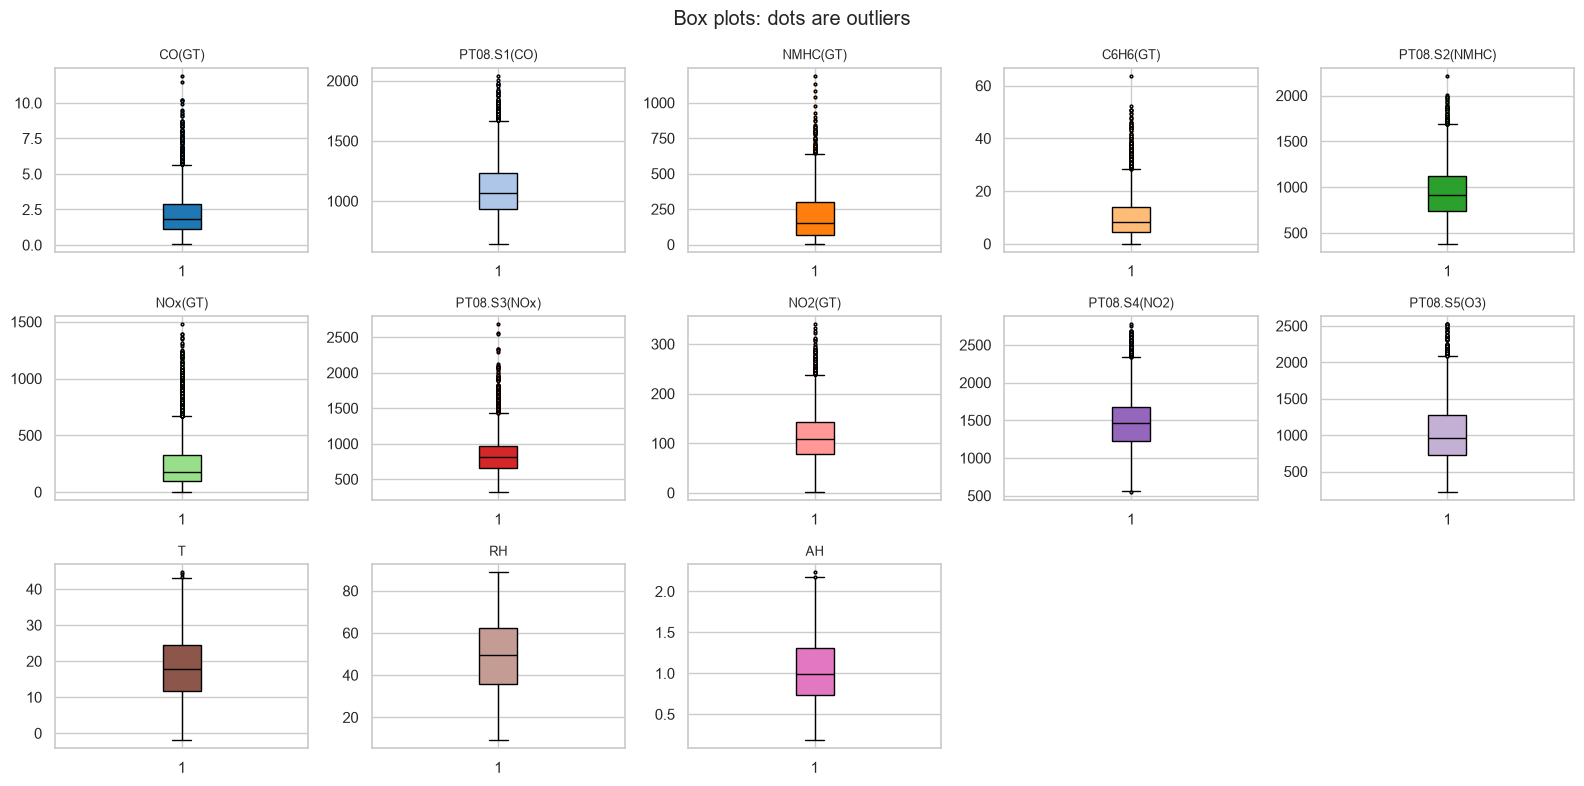

In [9]:
fig, axes = plt.subplots(3, 5, figsize=(16, 8))
for ax, col, c in zip(axes.ravel(), numeric.columns, colors):
    ax.boxplot(numeric[col].dropna(), patch_artist=True, boxprops={"facecolor": c},
               medianprops={"color": "black"}, flierprops={"markerfacecolor": c, "markersize": 2})
    ax.set_title(col, fontsize=9)
for ax in axes.ravel()[len(numeric.columns):]:
    ax.axis("off")
plt.suptitle("Box plots: dots are outliers")
plt.tight_layout()
plt.show()

CO, NOx and benzene are right-skewed: low values are common, with occasional high-pollution spikes. This matches the paper.

### 3.5 Absolute humidity vs each variable (paper Fig. 5)

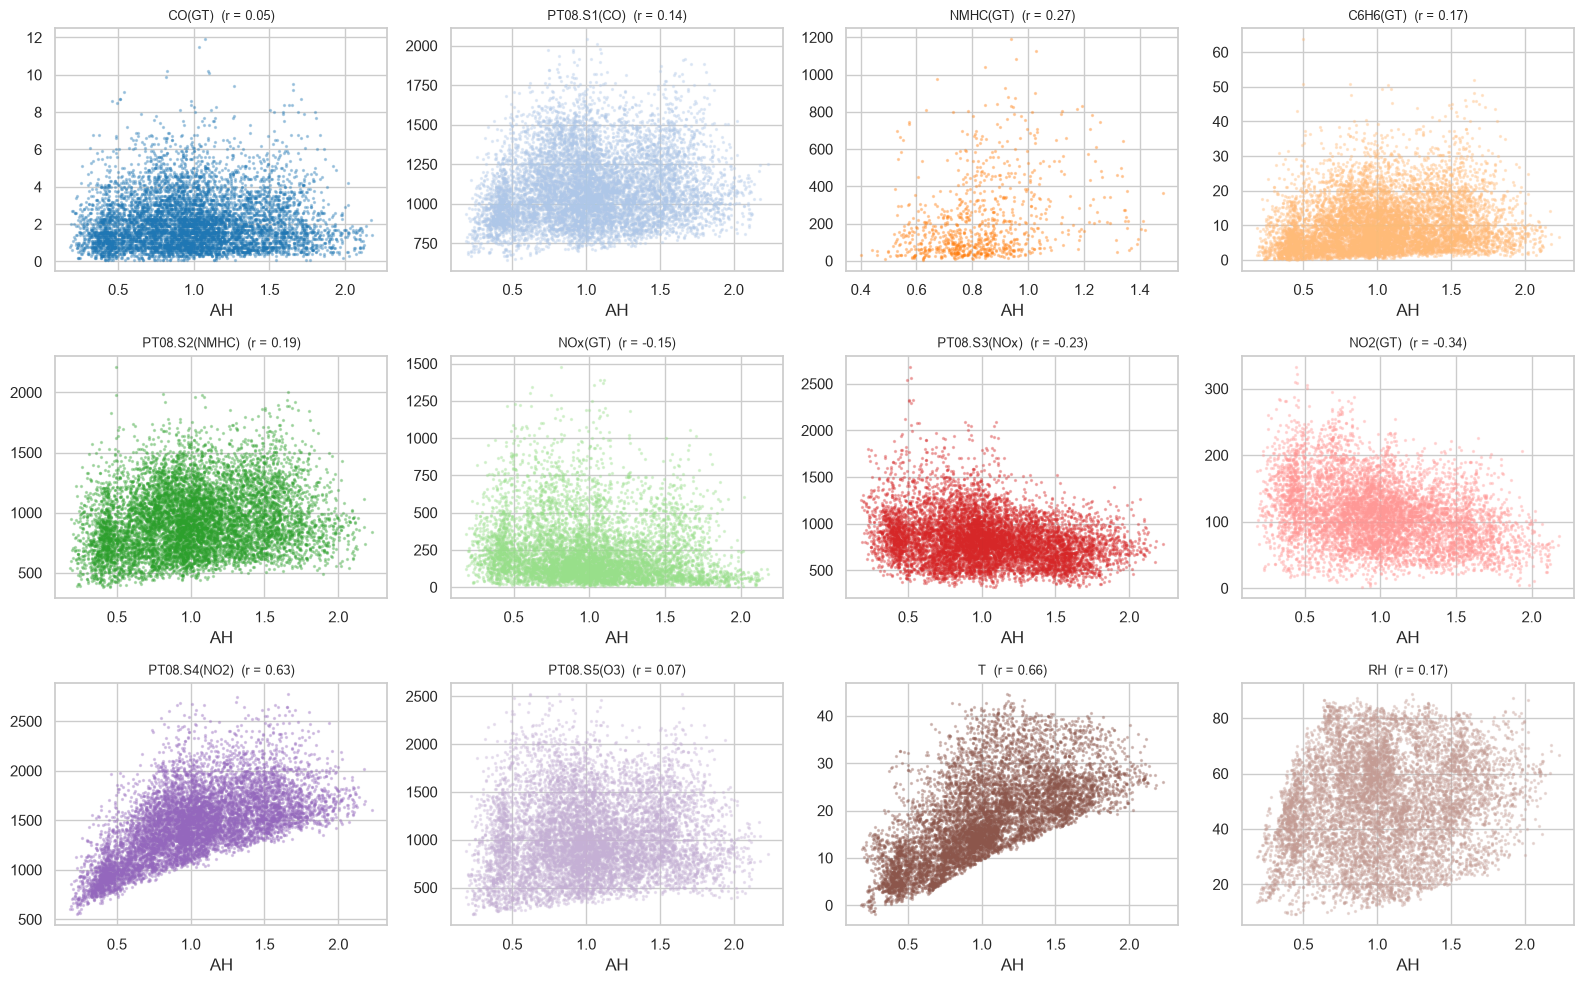

In [10]:
others = [c for c in numeric.columns if c != "AH"]
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col, c in zip(axes.ravel(), others, colors):
    ax.scatter(numeric["AH"], numeric[col], s=2, alpha=0.3, color=c)
    ax.set_xlabel("AH")
    ax.set_title(f"{col}  (r = {corr.loc['AH', col]:.2f})", fontsize=9)
for ax in axes.ravel()[len(others):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

As in the paper, temperature rises with absolute humidity, and nitrogen oxides fall slightly as humidity rises.

## 4. Preprocessing
The paper only says it used "outlier removal and correlation analysis" and an 80/20 split in time order. Where it gives no detail, we choose the simplest option:

1. **Drop *NMHC(GT)***: 90% of it is missing.
2. **Drop rows with missing values**: the simplest choice; the paper does not say how it handled them.
3. **Remove outliers**: a row is removed if any value lies outside 1.5 × IQR (the standard box-plot rule, as in Fig. 4). Like the paper, we do this on the whole dataset before splitting. Note that this also removes extreme hours from the test set, which makes the test a little easier.
4. **Split by time**: the first 80% of hours for training, the last 20% for testing. No shuffling, so the model never sees the future.
5. **Standardise** features and target (mean 0, std 1) using training data only. The paper's MSE values are almost exactly 1 − R², which only happens on a standardised target, so the paper must have done this too.

We use all 11 remaining measurements (5 sensors, 4 reference analysers, T, RH, AH) as features, because the paper analyses all of them.

In [11]:
df = raw.drop(columns="NMHC(GT)").dropna()
print("Rows after dropping missing values:", len(df))

value_cols = df.columns.drop("datetime")
q1, q3 = df[value_cols].quantile(0.25), df[value_cols].quantile(0.75)
iqr = q3 - q1
outlier = ((df[value_cols] < q1 - 1.5 * iqr) | (df[value_cols] > q3 + 1.5 * iqr)).any(axis=1)
df = df[~outlier].reset_index(drop=True)
print("Rows after removing outliers:   ", len(df))

FEATURES = [c for c in value_cols if c != TARGET]
split = int(len(df) * 0.8)
train, test = df.iloc[:split], df.iloc[split:]
print(f"Train: {len(train)} rows ({train.datetime.min():%d %b %Y} to {train.datetime.max():%d %b %Y})")
print(f"Test:  {len(test)} rows ({test.datetime.min():%d %b %Y} to {test.datetime.max():%d %b %Y})")
print("Features:", FEATURES)

Rows after dropping missing values: 6941
Rows after removing outliers:    6222
Train: 4977 rows (10 Mar 2004 to 31 Jan 2005)
Test:  1245 rows (31 Jan 2005 to 04 Apr 2005)
Features: ['CO(GT)', 'PT08.S1(CO)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']


In [12]:
x_scaler = StandardScaler().fit(train[FEATURES])
y_scaler = StandardScaler().fit(train[[TARGET]])

X_train = x_scaler.transform(train[FEATURES])
X_test = x_scaler.transform(test[FEATURES])
y_train = y_scaler.transform(train[[TARGET]]).ravel()
y_test = y_scaler.transform(test[[TARGET]]).ravel()

## 5. Models and evaluation
The paper's 10 models, its metrics (R², MAE, MSE, plus RMSE), and its Tables 3 and 4 written out so we can compare.

Train_R2 is also recorded: if it is much higher than the test R², the model is overfitting.

In [13]:
MODELS = {
    "Random Forest":     lambda p: RandomForestRegressor(random_state=SEED, n_jobs=-1, **p),
    "XGBoost":           lambda p: XGBRegressor(random_state=SEED, n_jobs=-1, **p),
    "LightGBM":          lambda p: LGBMRegressor(random_state=SEED, verbose=-1, **p),
    "Gradient Boosting": lambda p: GradientBoostingRegressor(random_state=SEED, **p),
    "CatBoost":          lambda p: CatBoostRegressor(random_seed=SEED, verbose=0, **p),
    "SVR":               lambda p: SVR(**p),
    "Decision Tree":     lambda p: DecisionTreeRegressor(random_state=SEED, **p),
    "KNN":               lambda p: KNeighborsRegressor(**p),
    "ElasticNet":        lambda p: ElasticNet(random_state=SEED, max_iter=10000, **p),
    "Bayesian Ridge":    lambda p: BayesianRidge(**p),
}


def make_model(name, params=None):
    return MODELS[name](params or {})


def scores(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"R2": r2_score(y_true, y_pred), "MAE": mean_absolute_error(y_true, y_pred),
            "MSE": mse, "RMSE": np.sqrt(mse)}


def evaluate(models, stage, X_tr=None, X_te=None):
    # Fit every model on the training set and score it on the test set
    X_tr = X_train if X_tr is None else X_tr
    X_te = X_test if X_te is None else X_te
    rows = []
    for name, model in models.items():
        model.fit(X_tr, y_train)
        rows.append({"Model": name, "Stage": stage, **scores(y_test, model.predict(X_te)),
                     "Train_R2": r2_score(y_train, model.predict(X_tr))})
    return pd.DataFrame(rows)

In [14]:
# Paper Table 3: the hyperparameters the authors found
PAPER_PARAMS = {
    "Random Forest":     {"max_depth": 36, "min_samples_split": 2, "n_estimators": 194},
    "XGBoost":           {"learning_rate": 0.12756, "max_depth": 9, "n_estimators": 55},
    "LightGBM":          {"learning_rate": 0.04287, "max_depth": 19, "n_estimators": 199},
    "Gradient Boosting": {"learning_rate": 0.04758, "max_depth": 9, "n_estimators": 143},
    "CatBoost":          {"depth": 9, "iterations": 188, "learning_rate": 0.09327},
    "SVR":               {"C": 72.50001, "epsilon": 0.01844},
    "Decision Tree":     {"max_depth": 49, "min_samples_split": 2},
    "KNN":               {"n_neighbors": 4},
    "ElasticNet":        {"alpha": 0.01015, "l1_ratio": 0.11281},
    "Bayesian Ridge":    {"alpha_1": 0.00676, "alpha_2": 0.00121, "lambda_1": 0.00017, "lambda_2": 0.009995},
}

# Paper Table 4: R2, MAE, MSE without and with Bayesian optimisation
PAPER_TABLE4 = pd.DataFrame(
    [
        ("Random Forest",     0.9984,  0.0209, 0.0015, 0.9985, 0.0207, 0.0014),
        ("XGBoost",           0.9965,  0.0416, 0.0035, 0.9985, 0.0232, 0.0014),
        ("LightGBM",          0.99744, 0.0343, 0.0025, 0.9981, 0.0287, 0.0018),
        ("Gradient Boosting", 0.9889,  0.0733, 0.0111, 0.9988, 0.0207, 0.0011),
        ("CatBoost",          0.9990,  0.0218, 0.0009, 0.9978, 0.0326, 0.0021),
        ("SVR",               0.9932,  0.0581, 0.0068, 0.9994, 0.0120, 0.0005),
        ("Decision Tree",     0.9950,  0.0453, 0.0050, 0.9950, 0.0453, 0.0050),
        ("KNN",               0.9511,  0.1482, 0.0493, 0.9541, 0.1440, 0.0463),
        ("ElasticNet",        0.2434,  0.6718, 0.7645, 0.8529, 0.2933, 0.1485),
        ("Bayesian Ridge",    0.8544,  0.2949, 0.1471, 0.8544, 0.2949, 0.1471),
    ],
    columns=["Model", "R2_default", "MAE_default", "MSE_default", "R2_tuned", "MAE_tuned", "MSE_tuned"],
)

## 6. Step 1: default settings ("No Optimization")

In [15]:
default_results = evaluate({name: make_model(name) for name in MODELS}, "Default")
default_results

,Model,Stage,R2,MAE,MSE,RMSE,Train_R2
0,Random Forest,Default,1.0000,0.0021,1.8610e-05,0.0043,1.0000
1,XGBoost,Default,0.9998,0.0071,1.0967e-04,0.0105,1.0000
2,LightGBM,Default,0.9999,0.0060,8.7067e-05,0.0093,0.9999
3,Gradient Boosting,Default,0.9999,0.0057,5.8901e-05,0.0077,0.9999
4,CatBoost,Default,0.9995,0.0141,3.6934e-04,0.0192,0.9999
5,SVR,Default,0.9783,0.0997,1.5505e-02,0.1245,0.9977
6,Decision Tree,Default,0.9999,0.0023,4.2371e-05,0.0065,1.0000
7,KNN,Default,0.9390,0.1651,4.3623e-02,0.2089,0.9877
8,ElasticNet,Default,0.4809,0.5372,3.7105e-01,0.6091,0.5993
9,Bayesian Ridge,Default,0.9434,0.1554,4.0474e-02,0.2012,0.9845


**Result.** Without any tuning, the tree and boosting models already reach R² between 0.9995 and 1.0000, higher than the paper's 0.989–0.999. SVR scores 0.9783 (paper 0.9932) and KNN 0.9390 (paper 0.9511). ElasticNet is by far the weakest at 0.4809; the paper also has it last (0.2434). Bayesian Ridge scores 0.9434, higher than the paper's 0.8544.

## 7. Step 2: the paper's hyperparameters (Table 3)
If our setup matched the authors', these settings should give results close to their "Bayesian Optimization" column.

In [16]:
paper_param_results = evaluate({name: make_model(name, PAPER_PARAMS[name]) for name in MODELS}, "Paper params")
paper_param_results

,Model,Stage,R2,MAE,MSE,RMSE,Train_R2
0,Random Forest,Paper params,1.0000,0.0021,1.8370e-05,0.0043,1.0000
1,XGBoost,Paper params,0.9999,0.0065,9.6445e-05,0.0098,1.0000
2,LightGBM,Paper params,0.9999,0.0059,8.5131e-05,0.0092,0.9999
3,Gradient Boosting,Paper params,1.0000,0.0028,2.5197e-05,0.0050,1.0000
4,CatBoost,Paper params,0.9979,0.0270,1.4961e-03,0.0387,0.9997
5,SVR,Paper params,0.9959,0.0391,2.9057e-03,0.0539,0.9999
6,Decision Tree,Paper params,0.9999,0.0023,4.2371e-05,0.0065,1.0000
7,KNN,Paper params,0.9361,0.1677,4.5705e-02,0.2138,0.9887
8,ElasticNet,Paper params,0.9576,0.1302,3.0334e-02,0.1742,0.9830
9,Bayesian Ridge,Paper params,0.9434,0.1554,4.0475e-02,0.2012,0.9845


**Result.** The paper's settings help the models that are sensitive to them: SVR rises from 0.9783 to 0.9959, and ElasticNet from 0.4809 to 0.9576 (its small **alpha = 0.01015** removes most of the over-shrinking). The tree models stay at about 0.9999–1.0000. CatBoost drops slightly (0.9995 → 0.9979), probably because its deeper trees overfit a little.

## 8. Step 3: Bayesian optimisation
The paper tunes each model with **Bayesian optimisation** and **randomized cross-validation**. We use Optuna's TPE sampler (a Bayesian optimiser) and 5-fold shuffled cross-validation **on the training set only**. The test set is never used for tuning.

The search ranges below are copied from the paper's Results section. Ranges that span several orders of magnitude (C, alpha, learning rate) are searched on a log scale, so small and large values get an equal chance.

In [17]:
def search_space(name, trial):
    f, i = trial.suggest_float, trial.suggest_int
    if name == "Random Forest":
        return {"n_estimators": i("n_estimators", 10, 200), "max_depth": i("max_depth", 5, 50),
                "min_samples_split": i("min_samples_split", 2, 20)}
    if name in ("XGBoost", "LightGBM", "Gradient Boosting"):
        return {"n_estimators": i("n_estimators", 10, 200), "max_depth": i("max_depth", 3, 20),
                "learning_rate": f("learning_rate", 0.01, 0.3, log=True)}
    if name == "CatBoost":
        return {"iterations": i("iterations", 10, 200), "depth": i("depth", 3, 10),
                "learning_rate": f("learning_rate", 0.01, 0.3, log=True)}
    if name == "SVR":
        return {"C": f("C", 0.1, 100, log=True), "epsilon": f("epsilon", 0.01, 1, log=True)}
    if name == "Decision Tree":
        return {"max_depth": i("max_depth", 3, 50), "min_samples_split": i("min_samples_split", 2, 20)}
    if name == "KNN":
        return {"n_neighbors": i("n_neighbors", 1, 20)}
    if name == "ElasticNet":
        return {"alpha": f("alpha", 0.01, 10, log=True), "l1_ratio": f("l1_ratio", 0.1, 1)}
    if name == "Bayesian Ridge":
        return {k: f(k, 1e-6, 1e-2, log=True) for k in ("alpha_1", "alpha_2", "lambda_1", "lambda_2")}


def tune(name):
    cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

    def cv_error(trial):
        model = make_model(name, search_space(name, trial))
        return -cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_mean_squared_error").mean()

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(cv_error, n_trials=N_TRIALS)
    return study.best_params

In [18]:
best_params = {}
for name in MODELS:
    best_params[name] = tune(name)
    print(f"{name:18s} {best_params[name]}")

Random Forest      {'n_estimators': 198, 'max_depth': 8, 'min_samples_split': 2}
XGBoost            {'n_estimators': 185, 'max_depth': 5, 'learning_rate': 0.057910992518023}
LightGBM           {'n_estimators': 92, 'max_depth': 8, 'learning_rate': 0.08012737503998542}
Gradient Boosting  {'n_estimators': 131, 'max_depth': 8, 'learning_rate': 0.12635799429505615}
CatBoost           {'iterations': 177, 'depth': 3, 'learning_rate': 0.27102984047344075}
SVR                {'C': 50.72957033687833, 'epsilon': 0.010353677627159781}
Decision Tree      {'max_depth': 42, 'min_samples_split': 6}
KNN                {'n_neighbors': 7}
ElasticNet         {'alpha': 0.01090458456891785, 'l1_ratio': 0.47646779276550144}
Bayesian Ridge     {'alpha_1': 0.0015317343867314575, 'alpha_2': 0.003778890551242372, 'lambda_1': 6.3650520252347876e-06, 'lambda_2': 0.009778543884580883}


In [19]:
tuned_results = evaluate({name: make_model(name, best_params[name]) for name in MODELS}, "Bayesian Optimization")
tuned_results

,Model,Stage,R2,MAE,MSE,RMSE,Train_R2
0,Random Forest,Bayesian Optimization,1.0000,0.0019,1.6749e-05,0.0041,1.0000
1,XGBoost,Bayesian Optimization,0.9999,0.0056,7.9126e-05,0.0089,1.0000
2,LightGBM,Bayesian Optimization,0.9999,0.0060,8.6776e-05,0.0093,0.9999
3,Gradient Boosting,Bayesian Optimization,1.0000,0.0026,2.1616e-05,0.0046,1.0000
4,CatBoost,Bayesian Optimization,0.9996,0.0126,2.7975e-04,0.0167,0.9997
5,SVR,Bayesian Optimization,0.9979,0.0278,1.5298e-03,0.0391,1.0000
6,Decision Tree,Bayesian Optimization,0.9999,0.0025,4.0703e-05,0.0064,1.0000
7,KNN,Bayesian Optimization,0.9411,0.1626,4.2122e-02,0.2052,0.9863
8,ElasticNet,Bayesian Optimization,0.9619,0.1220,2.7212e-02,0.1650,0.9825
9,Bayesian Ridge,Bayesian Optimization,0.9434,0.1554,4.0475e-02,0.2012,0.9845


**Result.** Tuning improved 9 of the 10 models; Bayesian Ridge stayed at 0.9434. Random Forest and Gradient Boosting reach R² 1.0000, and SVR rises to 0.9979 (C ≈ 50.7, ε ≈ 0.010, close to the paper's C = 72.5, ε = 0.018). ElasticNet gains the most, from 0.4809 to 0.9619. `Train_R2` is at or near 1.0000 for the tree models and only slightly above their test R², so there is no sign of serious overfitting.

## 9. Comparison with the paper (Table 4)

In [20]:
ours = (default_results.set_index("Model")[["R2", "MAE", "MSE"]].add_suffix("_default")
        .join(tuned_results.set_index("Model")[["R2", "MAE", "MSE"]].add_suffix("_tuned")))
comparison = ours.join(PAPER_TABLE4.set_index("Model"), lsuffix="_ours", rsuffix="_paper")
comparison = comparison[["R2_default_ours", "R2_default_paper", "R2_tuned_ours", "R2_tuned_paper",
                         "MAE_tuned_ours", "MAE_tuned_paper", "MSE_tuned_ours", "MSE_tuned_paper"]]
comparison.round(4)

,R2_default_ours,R2_default_paper,R2_tuned_ours,R2_tuned_paper,MAE_tuned_ours,MAE_tuned_paper,MSE_tuned_ours,MSE_tuned_paper
Model,,,,,,,,
Random Forest,1.0000,0.9984,1.0000,0.9985,0.0019,0.0207,0.0000,0.0014
XGBoost,0.9998,0.9965,0.9999,0.9985,0.0056,0.0232,0.0001,0.0014
LightGBM,0.9999,0.9974,0.9999,0.9981,0.0060,0.0287,0.0001,0.0018
Gradient Boosting,0.9999,0.9889,1.0000,0.9988,0.0026,0.0207,0.0000,0.0011
CatBoost,0.9995,0.9990,0.9996,0.9978,0.0126,0.0326,0.0003,0.0021
SVR,0.9783,0.9932,0.9979,0.9994,0.0278,0.0120,0.0015,0.0005
Decision Tree,0.9999,0.9950,0.9999,0.9950,0.0025,0.0453,0.0000,0.0050
KNN,0.9390,0.9511,0.9411,0.9541,0.1626,0.1440,0.0421,0.0463
ElasticNet,0.4809,0.2434,0.9619,0.8529,0.1220,0.2933,0.0272,0.1485


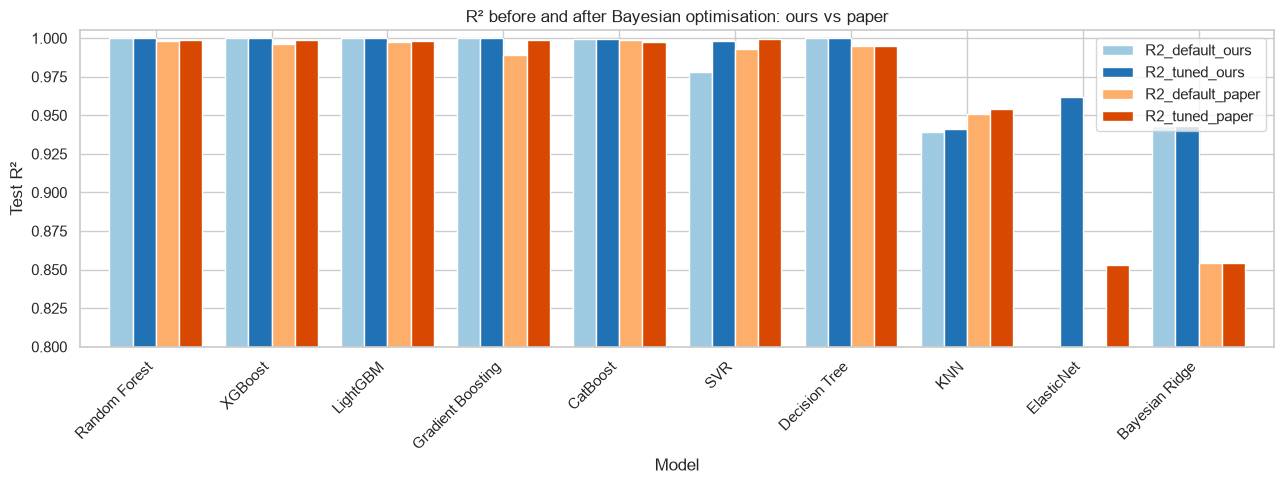

In [21]:
# Paper Fig. 6: R2 without and with optimisation, ours next to the paper's
plot_data = comparison[["R2_default_ours", "R2_tuned_ours", "R2_default_paper", "R2_tuned_paper"]]
plot_data.plot(kind="bar", figsize=(13, 5), ylim=(0.8, 1.005), width=0.8,
               color=["#9ecae1", "#2171b5", "#fdae6b", "#d94801"])
plt.ylabel("Test R²")
plt.title("R² before and after Bayesian optimisation: ours vs paper")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [22]:
best_tuned = tuned_results.sort_values("R2", ascending=False).iloc[0]
print(f"Our best tuned model: {best_tuned.Model} (R2 = {best_tuned.R2:.4f})")
print("Paper's best tuned model: SVR (R2 = 0.9994)")
print("Models where tuning improved R2:",
      [m for m in MODELS if tuned_results.set_index("Model").R2[m] > default_results.set_index("Model").R2[m]])

Our best tuned model: Random Forest (R2 = 1.0000)
Paper's best tuned model: SVR (R2 = 0.9994)
Models where tuning improved R2: ['Random Forest', 'XGBoost', 'LightGBM', 'Gradient Boosting', 'CatBoost', 'SVR', 'Decision Tree', 'KNN', 'ElasticNet']


**What matches the paper.**
- The ranking pattern: tree-based and boosting models score R² above 0.99 (ours 0.9996–1.0000 after tuning, paper 0.9950–0.9988); KNN and the linear models are clearly weaker; ElasticNet with default settings is by far the weakest.
- ElasticNet gains the most from tuning, because its default `alpha = 1` shrinks the coefficients far too much. Bayesian Ridge barely changes. Both match the paper.

**What does not match.**
- Our tree models score slightly *higher* than the paper's (about 1.000 vs about 0.998), and their MAE is about 3–18 times lower. The likely reason is that outlier removal also cleans the test set.
- Bayesian Ridge (0.9434 vs 0.8544) and tuned ElasticNet (0.9619 vs 0.8529) score higher in our run than in the paper.
- With all 11 features, SVR is **not** the best model, unlike the paper. Section 10 shows why.
- The paper does not report its target, missing-value handling, random seeds or library versions, so an exact number-for-number match is not possible. Our own choices for these details are stated at the top of this notebook and in Sections 1 and 4.

## 10. Reproducing the paper's headline result
The paper's best result is SVR with R² = 0.9994, MAE = 0.0120, MSE = 0.0005. Section 3 showed benzene is 0.98-correlated with the *PT08.S2(NMHC)* sensor. Here we check how close that relationship really is.

A simple cubic curve of PT08.S2 explains benzene with R2 = 0.99997


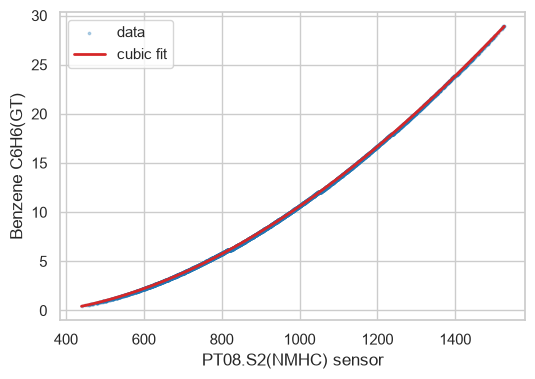

In [23]:
s2, benzene = df["PT08.S2(NMHC)"].to_numpy(), df[TARGET].to_numpy()
coef = np.polyfit(s2, benzene, deg=3)
fit = np.polyval(coef, s2)
print(f"A simple cubic curve of PT08.S2 explains benzene with R2 = {r2_score(benzene, fit):.5f}")

plt.figure(figsize=(6, 4))
plt.scatter(s2, benzene, s=3, alpha=0.3, color="tab:blue", label="data")
order = np.argsort(s2)
plt.plot(s2[order], fit[order], color="tab:red", lw=2, label="cubic fit")
plt.xlabel("PT08.S2(NMHC) sensor")
plt.ylabel("Benzene C6H6(GT)")
plt.legend()
plt.show()

Benzene is almost an exact mathematical function of one sensor. So any model that can learn a smooth curve from *PT08.S2(NMHC)* will score R² ≈ 0.999. This explains the paper's extremely high numbers.

Next we train SVR with the paper's Table 3 settings on different feature sets.

In [24]:
s2_col = [FEATURES.index("PT08.S2(NMHC)")]
svr_runs = pd.concat([
    evaluate({"SVR, all 11 features": make_model("SVR", PAPER_PARAMS["SVR"])}, "Paper params"),
    evaluate({"SVR, PT08.S2 only": make_model("SVR", PAPER_PARAMS["SVR"])}, "Paper params",
             X_tr=X_train[:, s2_col], X_te=X_test[:, s2_col]),
], ignore_index=True)
svr_runs.loc[len(svr_runs)] = {"Model": "SVR (paper, Table 4)", "Stage": "Bayesian Optimization",
                               "R2": 0.9994, "MAE": 0.0120, "MSE": 0.0005, "RMSE": np.sqrt(0.0005)}
svr_runs

,Model,Stage,R2,MAE,MSE,RMSE,Train_R2
0,"SVR, all 11 features",Paper params,0.9959,0.0391,2.9057e-03,0.0539,0.9999
1,"SVR, PT08.S2 only",Paper params,0.9999,0.0071,7.3443e-05,0.0086,0.9999
2,"SVR (paper, Table 4)",Bayesian Optimization,0.9994,0.0120,5.0000e-04,0.0224,NaN


**Result.** SVR with the paper's own hyperparameters, using only PT08.S2(NMHC), matches and even slightly beats the paper's headline (R² 0.9999 vs 0.9994). This also strongly suggests that benzene is the paper's unstated target.

With all 11 features, SVR scores lower (R² 0.9959). The extra variables add noise to SVR's distance-based kernel, while tree models simply ignore unhelpful features. In original units, the single-sensor SVR's mean error is only about 0.04 µg/m³ of benzene.

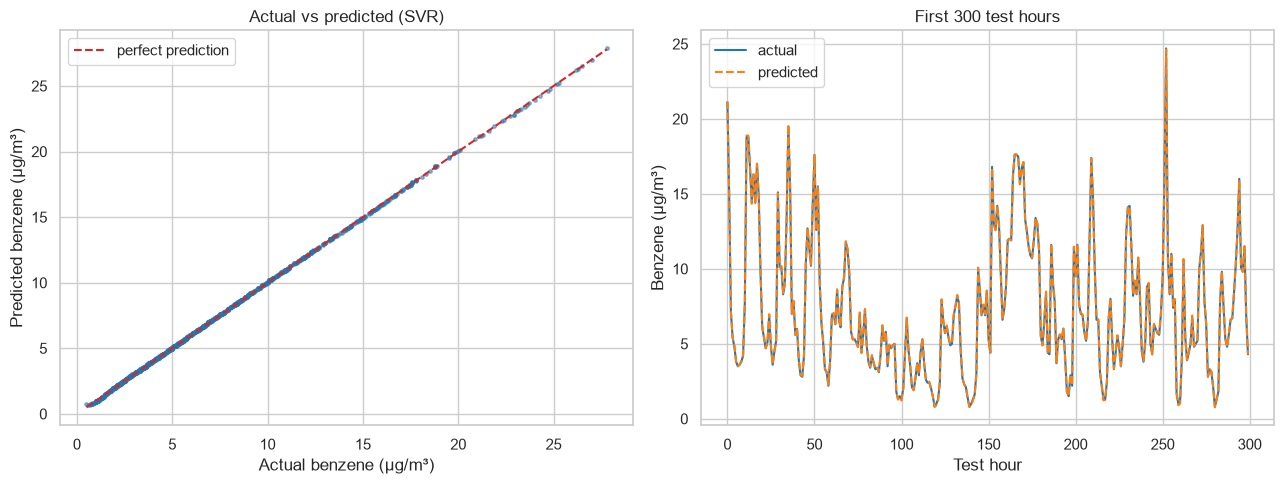

In [25]:
# Paper Fig. 7: actual vs predicted for the SVR, in original units (µg/m³)
svr = make_model("SVR", PAPER_PARAMS["SVR"]).fit(X_train[:, s2_col], y_train)
pred = y_scaler.inverse_transform(svr.predict(X_test[:, s2_col]).reshape(-1, 1)).ravel()
actual = test[TARGET].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(actual, pred, s=6, alpha=0.5, color="tab:blue")
axes[0].plot([actual.min(), actual.max()], [actual.min(), actual.max()], "--", color="tab:red", label="perfect prediction")
axes[0].set(xlabel="Actual benzene (µg/m³)", ylabel="Predicted benzene (µg/m³)", title="Actual vs predicted (SVR)")
axes[0].legend()
axes[1].plot(actual[:300], color="tab:blue", label="actual")
axes[1].plot(pred[:300], color="tab:orange", ls="--", label="predicted")
axes[1].set(xlabel="Test hour", ylabel="Benzene (µg/m³)", title="First 300 test hours")
axes[1].legend()
plt.tight_layout()
plt.show()

## 11. Stacking ensemble
Stacking trains several base models, then a small **meta-model** learns how to combine their predictions. The paper uses linear regression or gradient boosting as the meta-model and claims a **15–20% lower RMSE** than single models. It does not show a stacking row in its tables, so we measure it ourselves with the tuned models.

In [26]:
def stack(meta):
    base = [(name.replace(" ", "_"), make_model(name, best_params[name])) for name in MODELS]
    cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    return StackingRegressor(estimators=base, final_estimator=meta, cv=cv)


stack_results = evaluate({
    "Stacking (linear meta-model)": stack(LinearRegression()),
    "Stacking (gradient boosting meta-model)": stack(GradientBoostingRegressor(random_state=SEED)),
}, "Stacking")

best_single = tuned_results.RMSE.min()
mean_single = tuned_results.RMSE.mean()
stack_results["RMSE change vs best single model (%)"] = (stack_results.RMSE / best_single - 1) * 100
stack_results["RMSE change vs average single model (%)"] = (stack_results.RMSE / mean_single - 1) * 100

claim_holds = (stack_results["RMSE change vs best single model (%)"] <= -15).any()
print("Paper's claim (15-20% lower RMSE than the best single model) confirmed:", "YES" if claim_holds else "NO")
stack_results

Paper's claim (15-20% lower RMSE than the best single model) confirmed: NO


,Model,Stage,R2,MAE,MSE,RMSE,Train_R2,RMSE change vs best single model (%),RMSE change vs average single model (%)
0,Stacking (linear meta-model),Stacking,1.0000,0.0022,1.7086e-05,0.0041,1.0000,1.0005,-93.7423
1,Stacking (gradient boosting meta-model),Stacking,0.9999,0.0061,7.1404e-05,0.0085,0.9999,106.4732,-87.2075


A negative percentage means stacking has lower error, so it is better. Comparing against the best single model as well as the average: beating the average is easy, because the weak linear models pull it down.

**Result.** The paper's claim is **not confirmed**. The linear-meta stack (R² 1.0000, RMSE 0.0041) is 1.0% *worse* than the best single model (Random Forest), and the gradient-boosting stack is 106% worse. Both stacks beat the *average* single model by 87–94%, which may be how the paper measured its improvement. When the best single model is already almost perfect, there is nothing left for stacking to fix.

## 12. Which features matter? (Pearson, SHAP, PDP)
The paper explains its models with Pearson correlation, SHAP and partial dependence plots (PDP). We do the same with the best tuned tree model.

In [27]:
tree_models = ["Random Forest", "XGBoost", "LightGBM", "Gradient Boosting", "CatBoost", "Decision Tree"]
best_tree = tuned_results[tuned_results.Model.isin(tree_models)].sort_values("R2").iloc[-1].Model
explain_model = make_model(best_tree, best_params[best_tree]).fit(X_train, y_train)
X_test_df = pd.DataFrame(X_test, columns=FEATURES)
print("Explaining:", best_tree)

Explaining: Random Forest


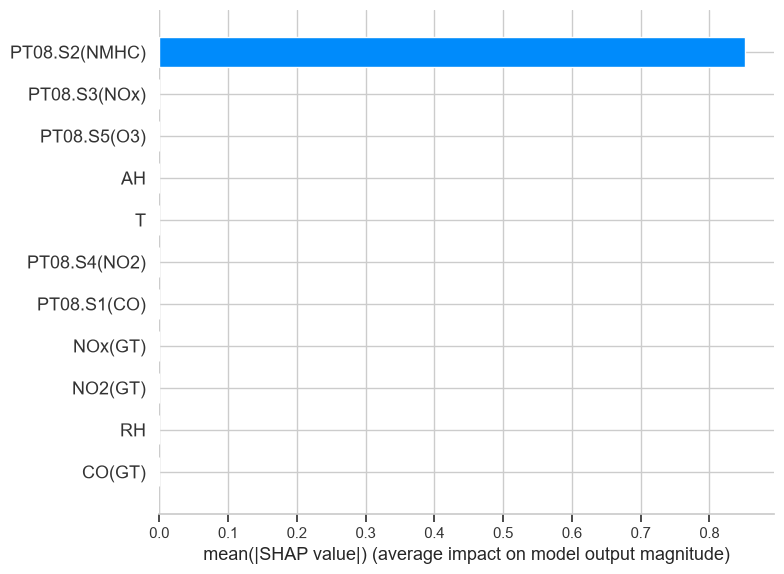

In [28]:
# SHAP: how much each feature pushes each prediction up or down
try:
    import shap
    shap_values = shap.TreeExplainer(explain_model).shap_values(X_test_df)
    shap.summary_plot(shap_values, X_test_df, plot_type="bar")
except ImportError:
    print("SHAP is not installed. Run `pip install shap` to see this plot.")

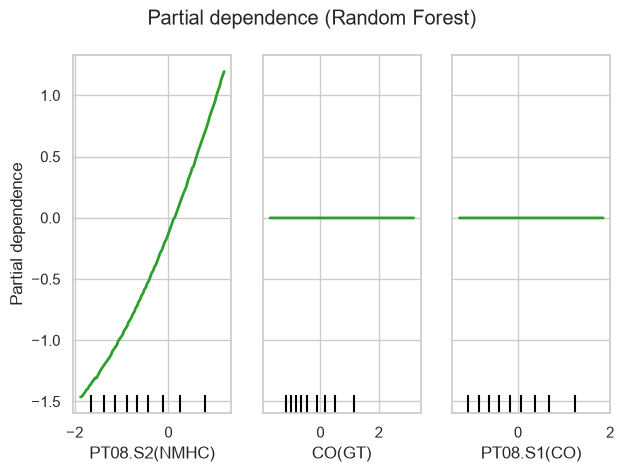

In [29]:
# PDP: how the prediction changes as one feature changes, with the others held fixed
top3 = corr.loc[FEATURES, TARGET].abs().sort_values(ascending=False).index[:3].tolist()
PartialDependenceDisplay.from_estimator(explain_model, X_test_df, features=top3,
                                        line_kw={"color": "tab:green", "lw": 2})
plt.suptitle(f"Partial dependence ({best_tree})")
plt.tight_layout()
plt.show()

**Result.** All three methods agree. Pearson correlation puts *PT08.S2(NMHC)* first (0.98). SHAP gives it a mean impact of about 0.85, while every other feature is close to zero. The partial dependence plot shows a smooth rising curve for *PT08.S2(NMHC)* and completely flat lines for *CO(GT)* and *PT08.S1(CO)*. The tuned Random Forest effectively uses one sensor, which confirms Section 10.

## 13. Final results

In [30]:
all_results = pd.concat([default_results, paper_param_results, tuned_results,
                         stack_results.iloc[:, :7], svr_runs], ignore_index=True)
all_results.to_csv("results_all_models.csv", index=False)
all_results.sort_values("R2", ascending=False).head(15).round(4)

,Model,Stage,R2,MAE,MSE,RMSE,Train_R2
20,Random Forest,Bayesian Optimization,1.0000,0.0019,0.0000,0.0041,1.0000
30,Stacking (linear meta-model),Stacking,1.0000,0.0022,0.0000,0.0041,1.0000
10,Random Forest,Paper params,1.0000,0.0021,0.0000,0.0043,1.0000
0,Random Forest,Default,1.0000,0.0021,0.0000,0.0043,1.0000
23,Gradient Boosting,Bayesian Optimization,1.0000,0.0026,0.0000,0.0046,1.0000
13,Gradient Boosting,Paper params,1.0000,0.0028,0.0000,0.0050,1.0000
26,Decision Tree,Bayesian Optimization,0.9999,0.0025,0.0000,0.0064,1.0000
16,Decision Tree,Paper params,0.9999,0.0023,0.0000,0.0065,1.0000
6,Decision Tree,Default,0.9999,0.0023,0.0000,0.0065,1.0000
3,Gradient Boosting,Default,0.9999,0.0057,0.0001,0.0077,0.9999


## 14. Conclusion

**Our numbers in one line.** Best tuned single model: Random Forest, R² 1.0000 (paper's best: SVR, 0.9994). SVR on *PT08.S2(NMHC)* alone: R² 0.9999. Stacking: no improvement over the best single model.

**Reproduced.**
- The full method: 80/20 time-ordered split, outlier removal, 10 regression models, Bayesian optimisation with the paper's search ranges and randomized cross-validation, stacking, and explanation with Pearson/SHAP/PDP.
- The overall result: tree and boosting models reach R² above 0.99, and the linear models are clearly weaker.
- The headline: SVR with the paper's Table 3 settings reaches R² ≈ 0.9999 (paper: 0.9994) when it uses the *`PT08.S2(NMHC)`* sensor.

**Not reproduced exactly, and why.**
- The paper does not name its target, its missing-value handling, its random seeds or its library versions, so individual numbers differ. Our tree models score slightly higher than the paper's, and with all 11 features SVR is not the best model.
- Some of the paper's own statistics (Tables 1–2, three correlations) do not match the dataset.
- The stacking result is shown in Section 11; the paper gives no stacking table to compare against.

**Main insight.** Benzene in this dataset is an almost exact function of one sensor (cubic fit R² ≈ 0.99997). The paper's 99.94% R² therefore shows that this relationship is easy to learn, not that the problem is hard. A fairer test would predict benzene **ahead in time** or **without** the `PT08.S2` sensor. This is a natural direction for Phase 2.

**Limitations.** One city, one year, one random seed. Shuffled cross-validation on time-series data, as the paper uses, can make tuning scores look better than the true future performance.